In [ ]:
TASK #1

In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
df = pd.read_csv("lab_ticket_resolution.csv")
print(df.shape)
print(df.dtypes)
print(df.describe(include="all"))
print(df.isna().sum())

(240, 6)
ticket_id                    str
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object
       ticket_id  complexity_score  lines_changed  team_experience_years  \
count        240        240.000000     240.000000             240.000000   
unique       240               NaN            NaN                    NaN   
top        T0001               NaN            NaN                    NaN   
freq           1               NaN            NaN                    NaN   
mean         NaN          5.491667      54.820833               6.105417   
std          NaN          2.979697      26.145017               3.391426   
min          NaN          1.000000       1.000000               0.500000   
25%          NaN          3.000000      33.000000               3.300000   
50%          NaN          5.500000      54.000000               5.800000   
75%          NaN   

In [ ]:
TASK #2

In [6]:
# Select the input features
X = df[['complexity_score', 'team_experience_years']]

# Select the target variable
y = df['resolution_hours']

print("Features (X):")
print(X.head())

print("\nTarget (y):")
print(y.head())

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

Features (X):
   complexity_score  team_experience_years
0                 6                    5.6
1                 9                   11.5
2                 6                    3.3
3                 5                    9.6
4                 3                    6.4

Target (y):
0    24.77
1    33.43
2    17.82
3    19.54
4    11.04
Name: resolution_hours, dtype: float64

Feature shape: (240, 2)
Target shape: (240,)


In [ ]:
TASK #3

In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))



Training rows: 192
Testing rows: 48


In [ ]:
TASK #4

In [9]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

dummy = DummyRegressor(strategy="mean")
dummy.fit(X_train, y_train)

dummy_predictions = dummy.predict(X_test)

mae = mean_absolute_error(y_test, dummy_predictions)
rmse = mean_squared_error(y_test, dummy_predictions) ** 0.5
r2 = r2_score(y_test, dummy_predictions)

print("Dummy MAE:", round(mae, 4))
print("Dummy RMSE:", round(rmse, 4))
print("Dummy R²:", round(r2, 4))

Dummy MAE: 9.114
Dummy RMSE: 10.5977
Dummy R²: -0.021


In [ ]:
TASK #5

In [10]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

print("MAE:", round(mean_absolute_error(
    y_test, linear_predictions), 4))

print("RMSE:", round(mean_squared_error(
    y_test, linear_predictions) ** 0.5, 4))

print("R²:", round(r2_score(
    y_test, linear_predictions), 4))

MAE: 2.906
RMSE: 3.5723
R²: 0.884


In [ ]:
TEACHER'S TASK IN CLASSROOM

In [14]:
# 1. Import libraries
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 2. Load the dataset
df = pd.read_csv("lab_ticket_resolution.csv")

# 3. Define features (X) and target (y)
X = df[["complexity_score", "team_experience_years"]]
y = df["resolution_hours"]

# 4. Split into training and testing sets (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# 5. Define the four models
models = {
    "Dummy Regression": DummyRegressor(strategy="mean"),

    "Linear Regression (Degree 1)": LinearRegression(),

    "Polynomial Regression (Degree 2)": Pipeline([
        ("poly", PolynomialFeatures(degree=2, include_bias=False)),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Polynomial Regression (Degree 3)": Pipeline([
        ("poly", PolynomialFeatures(degree=3, include_bias=False)),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ])
}

# 6. Train models and calculate evaluation metrics
results = []

for name, model in models.items():

    # Train the model
    model.fit(X_train, y_train)

    # Predict resolution hours
    y_pred = model.predict(X_test)

    # Calculate metrics
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    # Save results
    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2
    })

# 7. Display comparison table
results_df = pd.DataFrame(results)

print("MODEL COMPARISON")
display(results_df.round(4))

MODEL COMPARISON


,Model,MAE,RMSE,R²
0,Dummy Regression,9.1140,10.5977,-0.0210
1,Linear Regression (Degree 1),2.9060,3.5723,0.8840
2,Polynomial Regression (Degree 2),3.0202,3.7409,0.8728
3,Polynomial Regression (Degree 3),3.1398,3.9489,0.8582


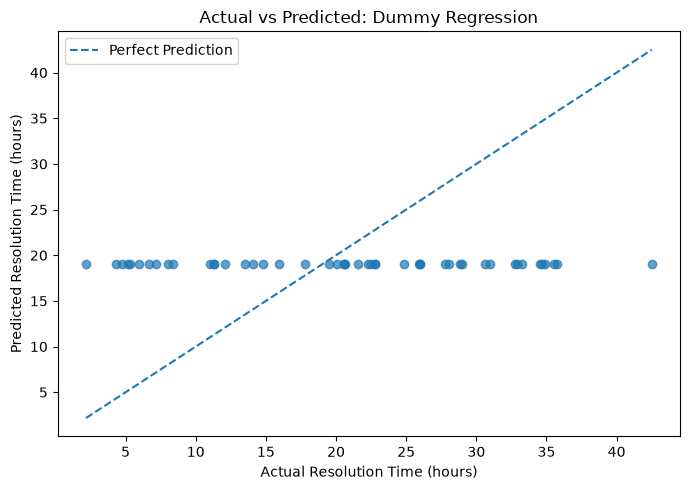

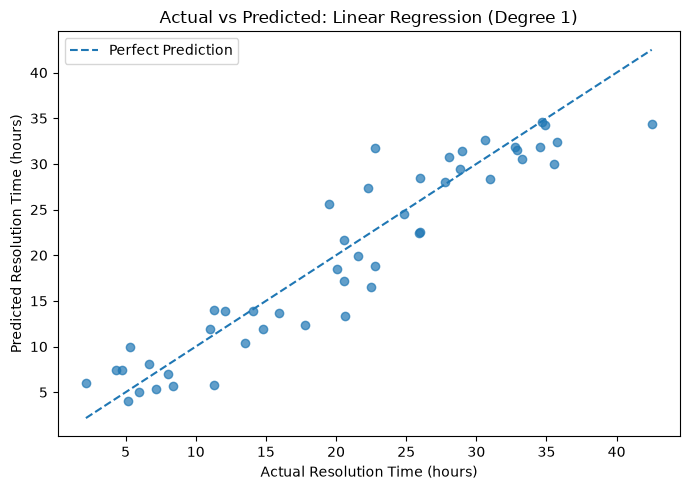

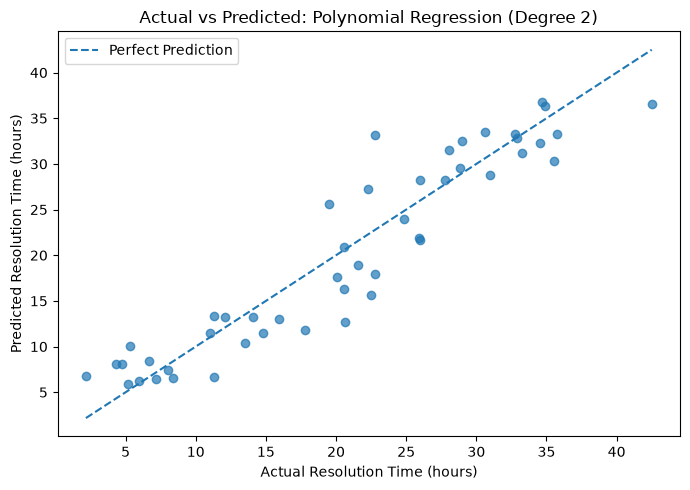

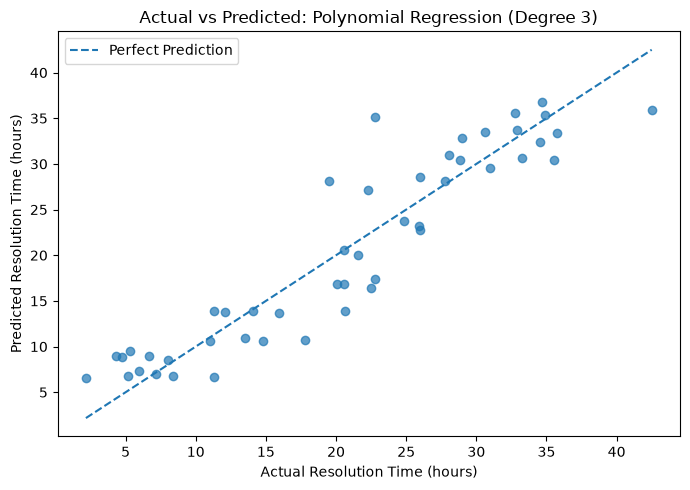

In [18]:
import matplotlib.pyplot as plt

for name, model in models.items():
    # Make predictions
    y_pred = model.predict(X_test)

    # Create a separate scatter plot
    plt.figure(figsize=(7, 5))
    plt.scatter(y_test, y_pred, alpha=0.7)

    # Add the perfect prediction reference line
    min_value = min(y_test.min(), y_pred.min())
    max_value = max(y_test.max(), y_pred.max())

    plt.plot(
        [min_value, max_value],
        [min_value, max_value],
        linestyle="--",
        label="Perfect Prediction"
    )

    plt.title(f"Actual vs Predicted: {name}")
    plt.xlabel("Actual Resolution Time (hours)")
    plt.ylabel("Predicted Resolution Time (hours)")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [ ]:
TASK #6

In [18]:

# TASK 6: Compare polynomial degrees 2 and 3
# using cross-validation on the training data only

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression

# 1. Load data
df = pd.read_csv("lab_ticket_resolution.csv")

# 2. Select features and target
X = df[["complexity_score", "team_experience_years"]]
y = df["resolution_hours"]

# 3. Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. Set up 5-fold cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# 5. Compare polynomial degrees using training data only
cv_results = {}

for degree in [2, 3]:

    polynomial_model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )

    scores = cross_val_score(
        polynomial_model,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_mean_absolute_error"
    )

    # Convert negative MAE scores into positive MAE
    mean_cv_mae = -scores.mean()
    std_cv_mae = scores.std()

    cv_results[degree] = mean_cv_mae

    print(f"\nPolynomial Degree {degree}")
    print(f"Mean CV MAE: {mean_cv_mae:.4f}")
    print(f"CV MAE Standard Deviation: {std_cv_mae:.4f}")

# 6. Select the degree with the lower cross-validation MAE
best_degree = min(cv_results, key=cv_results.get)

print("\nBest polynomial degree:", best_degree)
print("Lowest CV MAE:", round(cv_results[best_degree], 4))



Polynomial Degree 2
Mean CV MAE: 3.1313
CV MAE Standard Deviation: 0.3097

Polynomial Degree 3
Mean CV MAE: 3.1620
CV MAE Standard Deviation: 0.1882

Best polynomial degree: 2
Lowest CV MAE: 3.1313


In [ ]:
TASK #7a

In [20]:

# Try several alpha values
alpha_values = [0.001, 0.01, 0.1, 1, 10, 100]

ridge_pipeline = make_pipeline(
    StandardScaler(),
    Ridge()
)

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid={"ridge__alpha": alpha_values},
    scoring="neg_mean_absolute_error",
    cv=cv
)

# Tune using training data only
ridge_search.fit(X_train, y_train)

ridge_model = ridge_search.best_estimator_

print("Best Ridge alpha:", ridge_search.best_params_["ridge__alpha"])
print("Best Ridge CV MAE:", -ridge_search.best_score_)


Best Ridge alpha: 0.001
Best Ridge CV MAE: 3.1681758506214597


In [ ]:
TASK #7b

In [21]:

lasso_pipeline = make_pipeline(
    StandardScaler(),
    Lasso(max_iter=100000)
)

lasso_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid={"lasso__alpha": alpha_values},
    scoring="neg_mean_absolute_error",
    cv=cv
)

# Tune using training data only
lasso_search.fit(X_train, y_train)

lasso_model = lasso_search.best_estimator_

print("Best Lasso alpha:", lasso_search.best_params_["lasso__alpha"])
print("Best Lasso CV MAE:", -lasso_search.best_score_)


Best Lasso alpha: 0.001
Best Lasso CV MAE: 3.1682419077442643


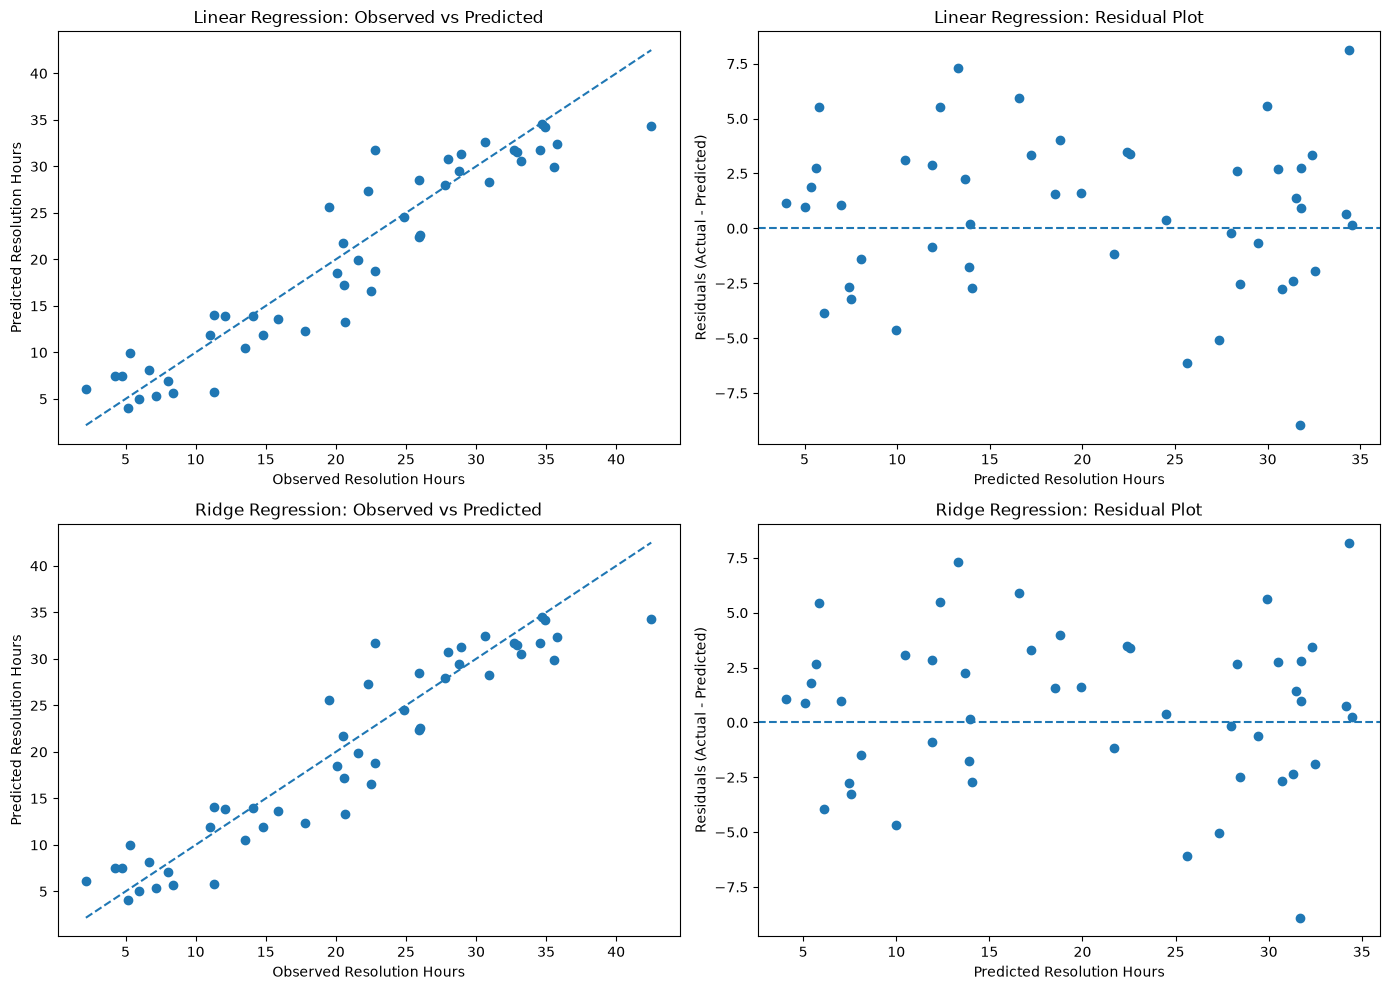


Linear Regression
-----------------------------------
MAE:  2.9060
MSE:  12.7611
RMSE: 3.5723
R²:   0.8840

Ridge Regression
-----------------------------------
MAE:  2.9052
MSE:  12.7487
RMSE: 3.5705
R²:   0.8841


In [15]:
# ==========================================
# TASK 8: VISUALIZE MODEL PERFORMANCE
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Load the dataset
df = pd.read_csv("lab_ticket_resolution.csv")

# 2. Select features and target
X = df[['complexity_score', 'team_experience_years']]
y = df['resolution_hours']

# 3. Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. Train Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# 5. Train Ridge Regression
ridge_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)
ridge_model.fit(X_train, y_train)

# 6. Generate predictions
y_pred_linear = linear_model.predict(X_test)
y_pred_ridge = ridge_model.predict(X_test)

# 7. Prepare models for plotting
models = [
    ("Linear Regression", y_pred_linear),
    ("Ridge Regression", y_pred_ridge)
]

# 8. Create four plots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for i, (name, predictions) in enumerate(models):

    # Observed vs predicted plot
    axes[i, 0].scatter(y_test, predictions)

    # Perfect prediction reference line
    minimum = min(y_test.min(), predictions.min())
    maximum = max(y_test.max(), predictions.max())

    axes[i, 0].plot(
        [minimum, maximum],
        [minimum, maximum],
        linestyle='--'
    )

    axes[i, 0].set_title(f'{name}: Observed vs Predicted')
    axes[i, 0].set_xlabel('Observed Resolution Hours')
    axes[i, 0].set_ylabel('Predicted Resolution Hours')

    # Calculate residuals
    residuals = y_test - predictions

    # Residual plot
    axes[i, 1].scatter(predictions, residuals)
    axes[i, 1].axhline(y=0, linestyle='--')

    axes[i, 1].set_title(f'{name}: Residual Plot')
    axes[i, 1].set_xlabel('Predicted Resolution Hours')
    axes[i, 1].set_ylabel('Residuals (Actual - Predicted)')

plt.tight_layout()
plt.show()

# 9. Display model metrics
for name, predictions in models:
    print(f"\n{name}")
    print("-" * 35)
    print(f"MAE:  {mean_absolute_error(y_test, predictions):.4f}")
    print(f"MSE:  {mean_squared_error(y_test, predictions):.4f}")
    print(f"RMSE: {np.sqrt(mean_squared_error(y_test, predictions)):.4f}")
    print(f"R²:   {r2_score(y_test, predictions):.4f}")

In [16]:
# ==========================================
# TASK 9: FINAL MODEL COMPARISON
# ==========================================

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. Load the dataset
df = pd.read_csv("lab_ticket_resolution.csv")

# 2. Select features and target
X = df[['complexity_score', 'team_experience_years']]
y = df['resolution_hours']

# 3. Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. Set up cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# 5. Create models
models = {
    "Dummy Baseline": DummyRegressor(strategy='mean'),

    "Linear Regression": make_pipeline(
        StandardScaler(),
        LinearRegression()
    ),

    "Polynomial Degree 2": make_pipeline(
        PolynomialFeatures(degree=2, include_bias=False),
        StandardScaler(),
        LinearRegression()
    ),

    "Polynomial Degree 3": make_pipeline(
        PolynomialFeatures(degree=3, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )
}

# 6. Tune Ridge alpha using training data
ridge_search = GridSearchCV(
    make_pipeline(StandardScaler(), Ridge()),
    param_grid={'ridge__alpha': [0.001, 0.01, 0.1, 1, 10, 100]},
    scoring='neg_mean_absolute_error',
    cv=cv
)
ridge_search.fit(X_train, y_train)

models["Ridge Regression"] = ridge_search.best_estimator_

# 7. Tune Lasso alpha using training data
lasso_search = GridSearchCV(
    make_pipeline(StandardScaler(), Lasso(max_iter=100000)),
    param_grid={'lasso__alpha': [0.001, 0.01, 0.1, 1, 10, 100]},
    scoring='neg_mean_absolute_error',
    cv=cv
)
lasso_search.fit(X_train, y_train)

models["Lasso Regression"] = lasso_search.best_estimator_

print("Best Ridge alpha:", ridge_search.best_params_['ridge__alpha'])
print("Best Lasso alpha:", lasso_search.best_params_['lasso__alpha'])

# 8. Train and evaluate every model
results = []

for name, model in models.items():

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "MSE": mean_squared_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R²": r2_score(y_test, predictions)
    })

# 9. Display comparison table
results_df = pd.DataFrame(results)

print("\nFINAL MODEL COMPARISON")
print(results_df.round(4).to_string(index=False))

# 10. Identify the best model for each metric
print("\nBEST MODEL BY METRIC")
print("Lowest MAE:", results_df.loc[results_df['MAE'].idxmin(), 'Model'])
print("Lowest MSE:", results_df.loc[results_df['MSE'].idxmin(), 'Model'])
print("Lowest RMSE:", results_df.loc[results_df['RMSE'].idxmin(), 'Model'])
print("Highest R²:", results_df.loc[results_df['R²'].idxmax(), 'Model'])

Best Ridge alpha: 0.001
Best Lasso alpha: 0.001

FINAL MODEL COMPARISON
              Model    MAE      MSE    RMSE      R²
     Dummy Baseline 9.1140 112.3109 10.5977 -0.0210
  Linear Regression 2.9060  12.7611  3.5723  0.8840
Polynomial Degree 2 3.0202  13.9944  3.7409  0.8728
Polynomial Degree 3 3.1398  15.5936  3.9489  0.8582
   Ridge Regression 2.9060  12.7611  3.5723  0.8840
   Lasso Regression 2.9061  12.7612  3.5723  0.8840

BEST MODEL BY METRIC
Lowest MAE: Ridge Regression
Lowest MSE: Ridge Regression
Lowest RMSE: Ridge Regression
Highest R²: Ridge Regression


In [ ]:
I compared six regression models: Dummy Regression, Linear Regression, Polynomial Regression of degrees 2 and 3, Ridge Regression, and Lasso Regression. I evaluated them using Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and the coefficient of determination (R²).

Ridge Regression achieved the best reported metrics, with an MAE of 2.9060, MSE of 12.7611, RMSE of 3.5723, and R² of 0.8840. However, its performance was practically identical to Linear Regression and Lasso Regression.

Both polynomial models performed slightly worse than the linear models, indicating that increasing model complexity did not improve test performance. The Dummy Regressor performed much worse, showing that the regression models learned useful relationships from the selected features.

I would select Linear Regression or Ridge Regression because they provide strong predictive performance with relatively low complexity. Before using the model in a real software team, I would validate it on real ticket data and ensure that all input features are available when a prediction is made.

In [ ]:
7. Analysis questions

In [ ]:
10.The mean baseline provides a simple reference point for evaluating more advanced models. It predicts the average resolution time for every ticket without considering any features. If a regression model cannot outperform this baseline, it may not be learning useful patterns from the data. In our results, the baseline had an MAE of 9.1140 and an R² of -0.0210, while Linear Regression achieved an MAE of 2.9060 and an R² of 0.8840. This shows that the regression models perform much better than simply predicting the mean.

In [ ]:
11.Ridge Regression has the lowest reported MAE of 2.9060 and the lowest reported RMSE of 3.5723. It also has the lowest MSE and highest R² in the comparison. However, its performance is practically identical to Linear Regression, so it does not have a meaningful advantage.

MAE measures average absolute prediction errors, whereas RMSE penalizes larger errors more heavily. Different models can perform differently under these metrics because RMSE is more sensitive to large prediction errors.

In [ ]:
12.No. Polynomial features did not improve performance on the test set. Linear Regression achieved an MAE of 2.9060, compared with 3.0202 for degree 2 and 3.1398 for degree 3. The increasing errors suggest that the more complex models did not generalize as well as the linear model.

Possible overfitting would be supported if a polynomial model performed better on training data but worse during cross-validation or on unseen test data. The test results alone suggest weaker generalization, but they do not conclusively prove overfitting.

In [ ]:
13.Ridge and Lasso performed almost identically to Linear Regression. Ridge achieved an MAE of 2.9060, while Lasso achieved 2.9061. The best alpha for both models was 0.001, indicating that very weak regularization was selected from the tested values.

Regularization penalizes large coefficients, encouraging smaller coefficient magnitudes. Ridge shrinks coefficients toward zero, while Lasso can shrink some coefficients completely to zero. In this experiment, the small alpha values resulted in little change in predictive performance. To confirm the effect on coefficient magnitudes, the fitted coefficients would need to be inspected.

In [ ]:
14.Scaling puts numerical features on comparable scales before regularization. Ridge and Lasso penalize coefficient sizes, so features measured on very different scales could otherwise receive unequal treatment. Including StandardScaler() helps ensure that the regularization penalty is applied more fairly across features. Using a pipeline also ensures that scaling is fitted on the training data during cross-validation, reducing the risk of data leakage.

In [ ]:
15.The lines_changed feature is a potential source of data leakage because the number of changed lines may only be known after the ticket has been implemented. Similarly, reopened may only be known after an initial resolution. If the goal is to predict resolution time when a ticket first arrives, using these features would give the model information unavailable at prediction time.

To avoid this problem, I used only complexity_score and team_experience_years as input features. I also excluded ticket_id because it is an identifier rather than a meaningful predictive feature.

In [ ]:
16.A random split may not be appropriate in these situations. If tickets were collected over several years, a random split could mix older and newer tickets across the training and test sets, failing to represent the task of predicting future tickets. A chronological split would be more suitable.

If multiple tickets came from the same customers or teams, a random split could place tickets from the same group in both sets. This could make test performance look better than performance on unseen groups. A group-based split, such as GroupKFold or GroupShuffleSplit, would help evaluate generalization to different customers or teams.

In [ ]:
17.Before deployment, I would:

1. Test on real data: Evaluate the model on representative software tickets rather than relying only on synthetic data.
2. Check data leakage: Confirm that every input feature is available when a prediction is requested.
3. Validate appropriately: Use chronological or group-based validation if tickets have time-based patterns or repeated customers and teams.
4. Inspect residuals: Look for systematic prediction errors and unusually large errors.
5. Evaluate different groups: Compare performance across ticket types, complexity levels, and teams.
6. Check data quality: Test how the model handles missing values, unusual inputs, and values outside the training range.
7. Monitor performance: Track prediction errors over time and retrain if the data patterns change.
8. Keep human oversight: Allow developers or project managers to review predictions rather than treating estimates as guaranteed resolution times.
Overall, I would consider Linear Regression or Ridge Regression as a starting point because both achieved strong and nearly identical results. However, the model should be validated on real-world data before being used to estimate actual ticket resolution times.